## Chest X-Ray AI Classification (Gemma-3 VLM) — Task 2 Base
Zero-shot evaluation of **Gemma-3-4b** for **Non-COVID Pneumonia** vs **COVID-19**.

---


### Quick Setup Instructions
* Run the installation cell below **once**.
* Click **"Restart session"** at the bottom of the output when it completes.
* Do not run the setup cell again after restarting. Go to the next cell.


In [1]:
import os
# Check if running in a Colab environment with GPU
if "COLAB_GPU" in os.environ:
    # Use unsloth[colab-new] for Colab to handle all dependencies.
    # This ensures compatible versions of bitsandbytes, accelerate, xformers, peft, trl, transformers etc.
    !pip install "unsloth[colab-new]==2026.1.3"
else:
    # For non-Colab environments or if no GPU, install basic unsloth.
    !pip install "unsloth==2026.1.3"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.6/66.6 kB 6.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.5 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of diffusers to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 61.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 143.1 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 46.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 102.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 120.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

### Model Loading


In [2]:
from unsloth import FastVisionModel # FastLanguageModel for LLMs
import torch

model, processor = FastVisionModel.from_pretrained(
    "unsloth/gemma-3-4b-it",
    load_in_4bit = True, # Use 4bit to reduce memory use. False for 16bit LoRA.
    use_gradient_checkpointing = "unsloth", # True or "unsloth" for long context
)
from unsloth import get_chat_template

processor = get_chat_template(
    processor,
    "gemma-3"
)


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.1.3: Fast Gemma3 patching. Transformers: 4.57.3.
   \\   /|    NVIDIA A100-SXM4-80GB. Num GPUs = 1. Max memory: 79.251 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 8.0. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Gemma3 does not support SDPA - switching to fast eager.


model.safetensors:   0%|          | 0.00/4.56G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/210 [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/70.0 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

### Dataset Loading + Results Helper


In [3]:
import torch
import random
SEED = 3407
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

from datasets import load_dataset
test_ds = load_dataset(
    "Henryayay/POLCOVID_task2_70_10_20",
    split="test"
)

from pathlib import Path
import pandas as pd
import re

TASK_ID = "Task2_base"
RESULTS_PROJECT_ROOT = Path(
    r"C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results"
)
LOCAL_RESULTS_ROOT = RESULTS_PROJECT_ROOT / "ICL" / "Task2"

def _slug(text):
    text = str(text).strip().replace(" ", "-")
    return re.sub(r"[^A-Za-z0-9._-]+", "_", text)

def record_and_save_run(y_true, y_pred, setup, model, accuracy_pct, task_id=TASK_ID, trigger_download=True):
    """Save predictions under Results/<method>/<task>/ with task, setup, model, and accuracy in the filename."""
    name_to_id = {
        "Non-COVID Pneumonia": 0,
        "COVID-19": 1
    }
    y_true = list(y_true)
    y_pred = list(y_pred)
    df = pd.DataFrame({
        "Index": range(len(y_true)),
        "True_Label_ID": [name_to_id.get(str(v).strip(), -1) for v in y_true],
        "Predicted_Label_ID": [name_to_id.get(str(v).strip(), -1) for v in y_pred],
        "True_Label_Name": y_true,
        "Predicted_Label_Name": y_pred,
    })

    meta = {
        "task_id": task_id,
        "setup": setup,
        "model": model,
        "accuracy_pct": float(accuracy_pct),
        "y_true": y_true,
        "y_pred": y_pred,
    }
    global RUN_META
    RUN_META = meta
    history = list(globals().get("RUN_HISTORY", []))
    key = (task_id, setup, model)
    history = [r for r in history if (r["task_id"], r["setup"], r["model"]) != key]
    history.append(meta)
    globals()["RUN_HISTORY"] = history

    acc_label = f"{float(accuracy_pct):.2f}pct"
    filename = f"{_slug(task_id)}_{_slug(setup)}_{_slug(model)}_acc{acc_label}.csv"

    dest_dir = None
    for candidate in (LOCAL_RESULTS_ROOT, Path.cwd() / "Results" / "ICL" / "Task2"):
        try:
            candidate.mkdir(parents=True, exist_ok=True)
            probe = candidate / ".write_test"
            probe.write_text("ok", encoding="utf-8")
            probe.unlink()
            dest_dir = candidate
            break
        except Exception:
            continue
    if dest_dir is None:
        dest_dir = Path.cwd() / "Results" / "ICL" / "Task2"
        dest_dir.mkdir(parents=True, exist_ok=True)

    dest_path = dest_dir / filename
    df.to_csv(dest_path, index=False)
    print(f"Saved predictions to: {dest_path}")

    errors = df[df["Predicted_Label_ID"] == -1]
    if len(errors) > 0:
        print(f"WARNING: {len(errors)} predictions could not be mapped to IDs!")
        print(errors["Predicted_Label_Name"].unique())
    else:
        print("Verification Passed: All predictions mapped correctly.")

    saved_on_pc = str(LOCAL_RESULTS_ROOT) in str(dest_path)
    if trigger_download and not saved_on_pc:
        cwd_copy = Path.cwd() / filename
        if cwd_copy.resolve() != dest_path.resolve():
            df.to_csv(cwd_copy, index=False)
        try:
            from google.colab import files
            print(f"Starting download for {filename}")
            print(f"If the browser save dialog appears, choose:\n{LOCAL_RESULTS_ROOT}")
            files.download(str(cwd_copy if cwd_copy.exists() else dest_path))
        except Exception as exc:
            print(f"Could not auto-download to your PC ({exc}). Copy this file to:\n{LOCAL_RESULTS_ROOT}")
    return dest_path


README.md:   0%|          | 0.00/624 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/303M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/43.2M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/87.4M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1596 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/228 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/456 [00:00<?, ? examples/s]

### Diagnostic Inference
* **Option A:** Sequential (commented out)
* **Option B:** Batched (`BATCH_SIZE=8`) — recommended on A100


#### Option A: Sequential


In [4]:
# OPTION A: Sequential evaluation (kept commented; Option B is the A100 path)
# from tqdm import tqdm
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import seaborn as sns
# import matplotlib.pyplot as plt
# from unsloth import FastVisionModel
#
# LABEL_MAP = {0: "Non-COVID Pneumonia", 1: "COVID-19"}
# FastVisionModel.for_inference(model)
# y_true, y_pred = [], []
# for sample in tqdm(test_ds):
#     actual_label = LABEL_MAP[sample["label"]]
#     y_true.append(actual_label)
#     messages = [{
#         "role": "user",
#         "content": [
#             {"type": "text", "text": "You are an expert radiologist. Analyze this chest X-ray and classify it as 'Non-COVID Pneumonia' or 'COVID-19'. Output only the diagnosis."},
#             {"type": "image"},
#         ],
#     }]
#     input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
#     inputs = processor(sample["image"], input_text, add_special_tokens=False, return_tensors="pt").to("cuda")
#     with torch.no_grad():
#         output = model.generate(**inputs, max_new_tokens=15, temperature=0.01, use_cache=True)
#     response = processor.decode(output[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)
#     if "COVID-19" in response:
#         pred_label = "COVID-19"
#     elif "Non-COVID Pneumonia" in response:
#         pred_label = "Non-COVID Pneumonia"
#     else:
#         pred_label = "Error"
#     y_pred.append(pred_label)
# print(classification_report(y_true, y_pred, labels=["Non-COVID Pneumonia", "COVID-19"]))


#### Option B: Batched (A100)


Starting batched evaluation (Batch Size: 8)...


100%|██████████| 57/57 [02:05<00:00,  2.20s/it]


Batched Gemma3 Task2 Accuracy: 50.00%

Detailed Report:
                     precision    recall  f1-score   support

Non-COVID Pneumonia       0.50      1.00      0.67       228
           COVID-19       0.00      0.00      0.00       228

           accuracy                           0.50       456
          macro avg       0.25      0.50      0.33       456
       weighted avg       0.25      0.50      0.33       456




/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


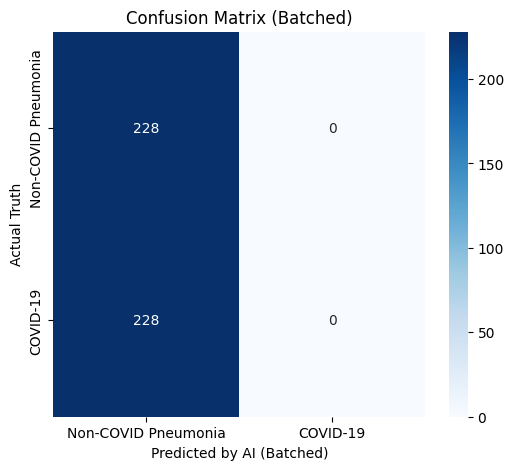

Saved predictions to: C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results/ICL/Task2/Task2_base_base_batched_gemma-3-4b-it_acc50.00pct.csv
Verification Passed: All predictions mapped correctly.


PosixPath('C:\\Users\\Henryayay\\OneDrive - The Hong Kong Polytechnic University\\Desktop\\AI xray classification project\\Results/ICL/Task2/Task2_base_base_batched_gemma-3-4b-it_acc50.00pct.csv')

In [5]:
from tqdm import tqdm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from unsloth import FastVisionModel
import torch

LABEL_MAP = {
    0: "Non-COVID Pneumonia",
    1: "COVID-19",
}

FastVisionModel.for_inference(model)
BATCH_SIZE = 8

y_true_batched = []
y_pred_batched = []

print(f"Starting batched evaluation (Batch Size: {BATCH_SIZE})...")

for i in tqdm(range(0, len(test_ds), BATCH_SIZE)):
    batch = test_ds[i : i + BATCH_SIZE]

    for lbl in batch["label"]:
        y_true_batched.append(LABEL_MAP[lbl])

    batch_messages = []
    batch_images = []
    for img in batch["image"]:
        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": "You are an expert radiologist. Analyze this chest X-ray and classify it as 'Non-COVID Pneumonia' or 'COVID-19'. Output only the diagnosis."
                    },
                    {"type": "image"}
                ],
            }
        ]
        input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
        batch_messages.append(input_text)
        batch_images.append([img])

    inputs = processor(
        text=batch_messages,
        images=batch_images,
        add_special_tokens=False,
        return_tensors="pt",
        padding=True
    ).to("cuda")

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=15,
            temperature=0.01,
            use_cache=True
        )

    prompt_len = inputs.input_ids.shape[1]
    responses = processor.batch_decode(outputs[:, prompt_len:], skip_special_tokens=True)

    for response in responses:
        # Check longer/more specific label first
        if "COVID-19" in response:
            pred_label = "COVID-19"
        elif "Non-COVID Pneumonia" in response:
            pred_label = "Non-COVID Pneumonia"
        else:
            pred_label = "Error"
        y_pred_batched.append(pred_label)

acc_batched = accuracy_score(y_true_batched, y_pred_batched)
accuracy_pct_batched = acc_batched * 100

print(f"\nBatched Gemma3 Task2 Accuracy: {accuracy_pct_batched:.2f}%")
print("\nDetailed Report:")
print(classification_report(y_true_batched, y_pred_batched, labels=["Non-COVID Pneumonia", "COVID-19"]))

cm_batched = confusion_matrix(y_true_batched, y_pred_batched, labels=["Non-COVID Pneumonia", "COVID-19"])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_batched, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-COVID Pneumonia", "COVID-19"],
            yticklabels=["Non-COVID Pneumonia", "COVID-19"])
plt.xlabel('Predicted by AI (Batched)')
plt.ylabel('Actual Truth')
plt.title('Confusion Matrix (Batched)')
plt.show()

record_and_save_run(
    y_true_batched,
    y_pred_batched,
    setup="base_batched",
    model="gemma-3-4b-it",
    accuracy_pct=accuracy_pct_batched,
)
